In [1]:
# ============================================
# EconoCausal - Week 1
# Exploratory Data Analysis (EDA)
# ============================================

print("EconoCausal Week 1 - EDA Started Successfully!")

EconoCausal Week 1 - EDA Started Successfully!


In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn -q

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv to Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv


In [5]:
file_name = "Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv"

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 64000
Columns: 12


In [6]:
# ============================================
# Step 7 - First 10 Rows
# ============================================

df.head(10)

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0
5,6,2) $100 - $200,134.83,0,1,Surburban,0,Phone,Womens E-Mail,1,0,0.0
6,9,3) $200 - $350,280.20,1,0,Surburban,1,Phone,Womens E-Mail,0,0,0.0
7,9,1) $0 - $100,46.42,0,1,Urban,0,Phone,Womens E-Mail,0,0,0.0
8,9,5) $500 - $750,675.07,1,1,Rural,1,Phone,Mens E-Mail,0,0,0.0
9,10,1) $0 - $100,32.84,0,1,Urban,1,Web,Womens E-Mail,0,0,0.0


In [7]:
# ============================================
# Step 8 - Dataset Structure and Data Quality
# ============================================

print("===== DATASET INFORMATION =====")
df.info()

print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

print("\n===== DUPLICATE ROWS =====")
print(df.duplicated().sum())

===== DATASET INFORMATION =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB

===== MISSING VALUES =====
recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0

In [8]:
# ============================================
# Step 9 - Descriptive Statistics
# ============================================

print("===== NUMERICAL DATA SUMMARY =====")

df.describe()

===== NUMERICAL DATA SUMMARY =====


,recency,history,mens,womens,newbie,visit,conversion,spend
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250,0.146781,0.009031,1.050908
std,3.507592,256.158608,0.497393,0.497526,0.499999,0.353890,0.094604,15.036448
min,1.000000,29.990000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000,1.000000,1.000000,499.000000


In [9]:
# ============================================
# Step 10 - Categorical Feature Analysis
# ============================================

categorical_columns = [
    "history_segment",
    "zip_code",
    "channel",
    "segment"
]

for column in categorical_columns:
    print("\n================================")
    print(f"{column.upper()} DISTRIBUTION")
    print("================================")
    print(df[column].value_counts())


HISTORY_SEGMENT DISTRIBUTION
history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64

ZIP_CODE DISTRIBUTION
zip_code
Surburban    28776
Urban        25661
Rural         9563
Name: count, dtype: int64

CHANNEL DISTRIBUTION
channel
Web             28217
Phone           28021
Multichannel     7762
Name: count, dtype: int64

SEGMENT DISTRIBUTION
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


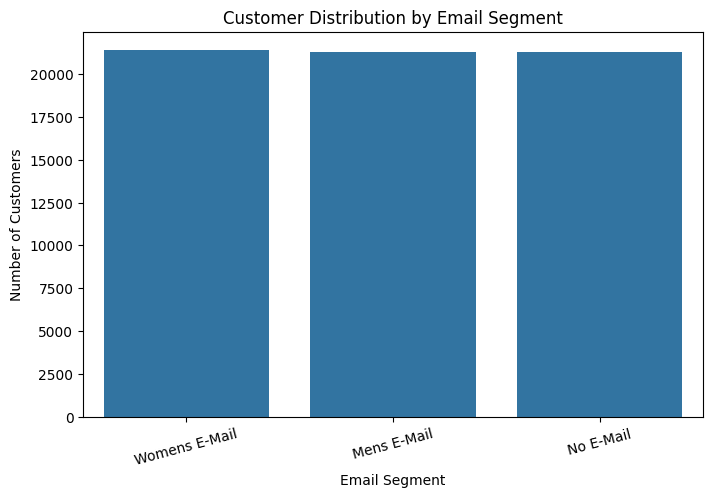

In [10]:
# ============================================
# Step 11 - Customer Segment Distribution
# ============================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="segment",
    order=df["segment"].value_counts().index
)

plt.title("Customer Distribution by Email Segment")
plt.xlabel("Email Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

===== CONVERSION RATE BY EMAIL SEGMENT =====


,Conversion Rate (%)
segment,
Mens E-Mail,1.25
Womens E-Mail,0.88
No E-Mail,0.57


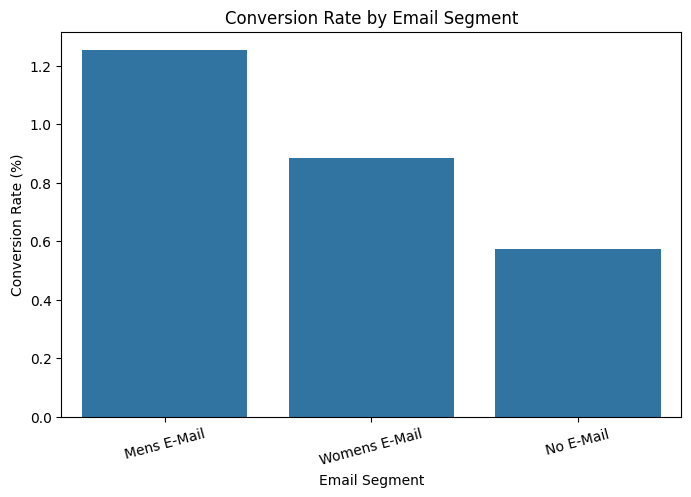

In [11]:
# ============================================
# Step 12 - Conversion Rate by Email Segment
# ============================================

conversion_by_segment = (
    df.groupby("segment")["conversion"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print("===== CONVERSION RATE BY EMAIL SEGMENT =====")
display(
    conversion_by_segment.to_frame("Conversion Rate (%)").round(2)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=conversion_by_segment.index,
    y=conversion_by_segment.values
)

plt.title("Conversion Rate by Email Segment")
plt.xlabel("Email Segment")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=15)

plt.show()

===== AVERAGE SPEND BY EMAIL SEGMENT =====


,Average Spend
segment,
Mens E-Mail,1.42
Womens E-Mail,1.08
No E-Mail,0.65


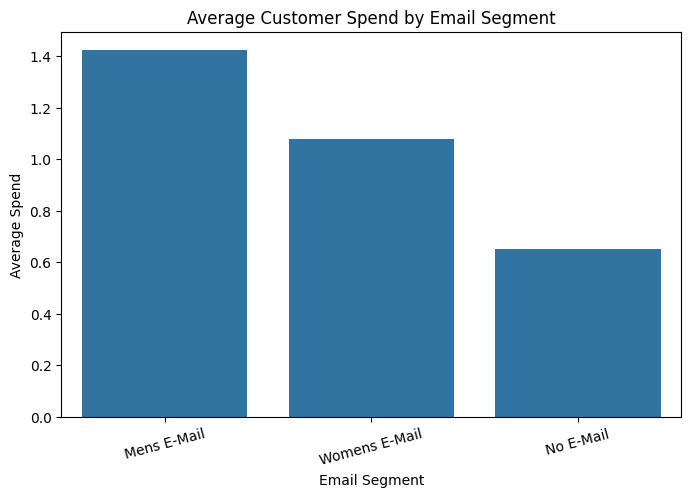

In [12]:
# ============================================
# Step 13 - Average Spend by Email Segment
# ============================================

spend_by_segment = (
    df.groupby("segment")["spend"]
      .mean()
      .sort_values(ascending=False)
)

print("===== AVERAGE SPEND BY EMAIL SEGMENT =====")

display(
    spend_by_segment.to_frame("Average Spend").round(2)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=spend_by_segment.index,
    y=spend_by_segment.values
)

plt.title("Average Customer Spend by Email Segment")
plt.xlabel("Email Segment")
plt.ylabel("Average Spend")
plt.xticks(rotation=15)

plt.show()

In [13]:
# ============================================
# Step 14 - Customer Behaviour by Email Segment
# ============================================

segment_behavior = (
    df.groupby("segment")
      .agg(
          Customers=("segment", "count"),
          Average_Recency=("recency", "mean"),
          Average_History=("history", "mean"),
          Average_Visits=("visit", "mean"),
          Conversion_Rate=("conversion", "mean"),
          Average_Spend=("spend", "mean")
    )
)

segment_behavior["Conversion_Rate"] = (
    segment_behavior["Conversion_Rate"] * 100
)

print("===== CUSTOMER BEHAVIOUR BY EMAIL SEGMENT =====")

display(
    segment_behavior.round(2)
)

===== CUSTOMER BEHAVIOUR BY EMAIL SEGMENT =====


,Customers,Average_Recency,Average_History,Average_Visits,Conversion_Rate,Average_Spend
segment,,,,,,
Mens E-Mail,21307,5.77,242.84,0.18,1.25,1.42
No E-Mail,21306,5.75,240.88,0.11,0.57,0.65
Womens E-Mail,21387,5.77,242.54,0.15,0.88,1.08


===== CORRELATION MATRIX =====


,recency,history,mens,womens,newbie,visit,conversion,spend
recency,1.00,-0.25,-0.03,-0.03,-0.05,-0.07,-0.02,-0.02
history,-0.25,1.00,0.11,0.11,0.22,0.07,0.03,0.02
mens,-0.03,0.11,1.00,-0.82,0.02,0.01,0.00,0.01
womens,-0.03,0.11,-0.82,1.00,0.02,0.05,0.01,0.00
newbie,-0.05,0.22,0.02,0.02,1.00,-0.07,-0.01,-0.01
visit,-0.07,0.07,0.01,0.05,-0.07,1.00,0.23,0.17
conversion,-0.02,0.03,0.00,0.01,-0.01,0.23,1.00,0.73
spend,-0.02,0.02,0.01,0.00,-0.01,0.17,0.73,1.00


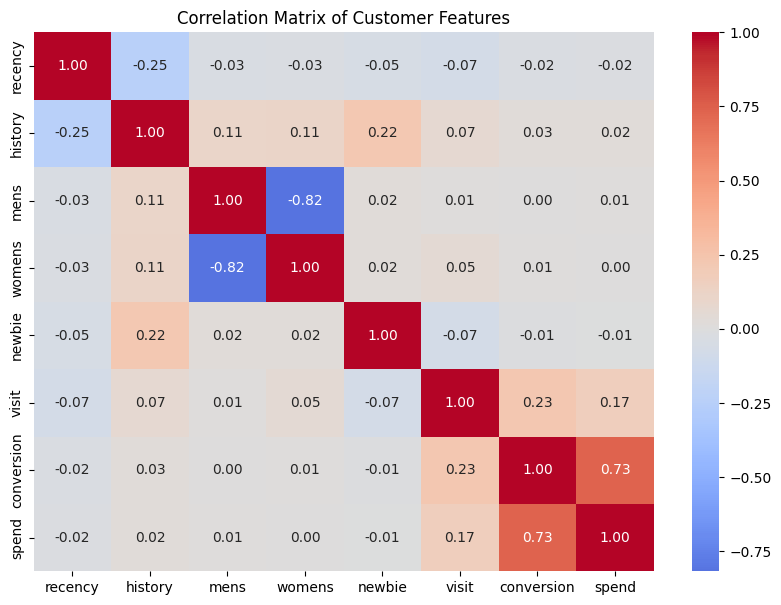

In [14]:
# ============================================
# Step 15 - Correlation Analysis
# ============================================

numeric_columns = [
    "recency",
    "history",
    "mens",
    "womens",
    "newbie",
    "visit",
    "conversion",
    "spend"
]

correlation_matrix = df[numeric_columns].corr()

print("===== CORRELATION MATRIX =====")

display(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Customer Features")
plt.show()

In [15]:
# ============================================
# Step 16 - Email vs No Email Comparison
# ============================================

df["email_treatment"] = np.where(
    df["segment"] == "No E-Mail",
    "No Email",
    "Email"
)

email_comparison = (
    df.groupby("email_treatment")
      .agg(
          Customers=("email_treatment", "count"),
          Conversion_Rate=("conversion", "mean"),
          Average_Spend=("spend", "mean"),
          Average_Visits=("visit", "mean")
    )
)

email_comparison["Conversion_Rate"] = (
    email_comparison["Conversion_Rate"] * 100
)

print("===== EMAIL VS NO EMAIL COMPARISON =====")

display(
    email_comparison.round(2)
)

===== EMAIL VS NO EMAIL COMPARISON =====


,Customers,Conversion_Rate,Average_Spend,Average_Visits
email_treatment,,,,
Email,42694,1.07,1.25,0.17
No Email,21306,0.57,0.65,0.11


In [16]:
# ============================================
# Step 17 - Week 1 EDA Key Findings
# ============================================

print("================================================")
print("        ECONOCAUSAL - WEEK 1 EDA FINDINGS")
print("================================================")

print("""
1. Dataset contains 64,000 customer records and 12 original features.

2. No missing values were found in any of the original columns.

3. The dataset contains 6,562 duplicate rows, which should be
   considered during later data preparation/modeling.

4. The overall conversion rate is approximately 0.90%.

5. Among email segments, Mens E-Mail has the highest observed
   conversion rate (1.25%), followed by Womens E-Mail (0.88%)
   and No E-Mail (0.57%).

6. Average spend is also highest for Mens E-Mail (1.42),
   followed by Womens E-Mail (1.08) and No E-Mail (0.65).

7. When both email groups are combined, the Email group has an
   observed conversion rate of 1.07%, compared with 0.57% for
   the No Email group.

8. Conversion and spend show a strong positive correlation
   (approximately 0.73).

9. These are observational findings and do not establish that
   sending an email caused the observed improvement.

10. The next causal modeling stage will estimate the treatment
    effect while accounting for customer characteristics.
""")

        ECONOCAUSAL - WEEK 1 EDA FINDINGS

1. Dataset contains 64,000 customer records and 12 original features.

2. No missing values were found in any of the original columns.

3. The dataset contains 6,562 duplicate rows, which should be
   considered during later data preparation/modeling.

4. The overall conversion rate is approximately 0.90%.

5. Among email segments, Mens E-Mail has the highest observed
   conversion rate (1.25%), followed by Womens E-Mail (0.88%)
   and No E-Mail (0.57%).

6. Average spend is also highest for Mens E-Mail (1.42),
   followed by Womens E-Mail (1.08) and No E-Mail (0.65).

7. When both email groups are combined, the Email group has an
   observed conversion rate of 1.07%, compared with 0.57% for
   the No Email group.

8. Conversion and spend show a strong positive correlation
   (approximately 0.73).

9. These are observational findings and do not establish that
   sending an email caused the observed improvement.

10. The next causal modeling st